# Computer Vision — Lab 6: Lab Tasks (CLO-2)
**Name:** Sarim Azhar  **Roll No:** 247076
**Instructor:** Ayesha Sahar

- **Lab Task 1 (5 marks):** Harris corner detection on my own image, three thresholds compared, rotation & resize test, and why Harris is not scale invariant.
- **Lab Task 2 (5 marks):** SIFT matching on two overlapping photos with Lowe's ratio test, homography with RANSAC (inlier count), and panorama stitching.

## Setup — Import Libraries

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


### Upload images (Google Colab)
Run the cell below. It asks for **three uploads, one at a time** (any filename works):
1. **Task 1 image** — any photo with clear corners (building, window, bookshelf, keyboard…)
2. **Left photo** and 3. **Right photo** — two overlapping photos of the same scene. Stand in one place and just **turn the phone** slightly between shots (about 30–50% overlap).

In [3]:
# Default paths (used only when NOT running in Colab)
TASK1_IMAGE = "task1.jpg"
LEFT_IMAGE  = "left.jpg"
RIGHT_IMAGE = "right.jpg"

try:
    from google.colab import files

    def ask_upload(label):
        print(f"\n>>> Upload {label}")
        up = files.upload()
        if not up:
            raise RuntimeError(f"No file uploaded for {label}.")
        name = list(up.keys())[0]          # whatever the file is called, use it
        print("    using:", name)
        return name

    TASK1_IMAGE = ask_upload("the Task 1 image (photo with clear corners)")
    LEFT_IMAGE  = ask_upload("the LEFT photo for the panorama")
    RIGHT_IMAGE = ask_upload("the RIGHT photo for the panorama")
except ImportError:
    print("Not running in Colab — using the default paths above.")

print("\nTask 1 image:", TASK1_IMAGE)
print("Left image  :", LEFT_IMAGE)
print("Right image :", RIGHT_IMAGE)


>>> Upload the Task 1 image (photo with clear corners)


Saving unnamed (1).webp to unnamed (1).webp
Saving unnamed.webp to unnamed.webp
    using: unnamed (1).webp

>>> Upload the LEFT photo for the panorama


Saving unnamed (1).webp to unnamed (1) (1).webp
Saving unnamed.webp to unnamed (2).webp
    using: unnamed (1) (1).webp

>>> Upload the RIGHT photo for the panorama


Saving unnamed.webp to unnamed (3).webp
    using: unnamed (3).webp

Task 1 image: unnamed (1).webp
Left image  : unnamed (1) (1).webp
Right image : unnamed (3).webp


In [15]:
def load_image(path, max_width=1000):
    """Load an image (BGR) and shrink large phone photos so SIFT and stitching stay fast."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not load '{path}'. Check the filename/path.")
    h, w = img.shape[:2]
    if w > max_width:
        scale = max_width / w
        img = cv2.resize(img, (max_width, int(h * scale)), interpolation=cv2.INTER_AREA)
    return img

---
# Lab Task 1 — Harris Corner Detection
## 1.1 Load my image and detect corners
Harris looks at how intensity changes when a small window is shifted. Flat region → no change, edge → change in one direction, corner → change in all directions.
The response is $R = \det(M) - k\,(\mathrm{trace}\,M)^2$, where $M$ is the structure tensor built from gradients $I_x, I_y$.

Parameters: `blockSize = 2`, `ksize = 3` (3×3 Sobel), `k = 0.04`, threshold = 1% of the maximum response.

Image size: (330, 330, 3)
Corners detected (threshold = 0.01 x max): 145


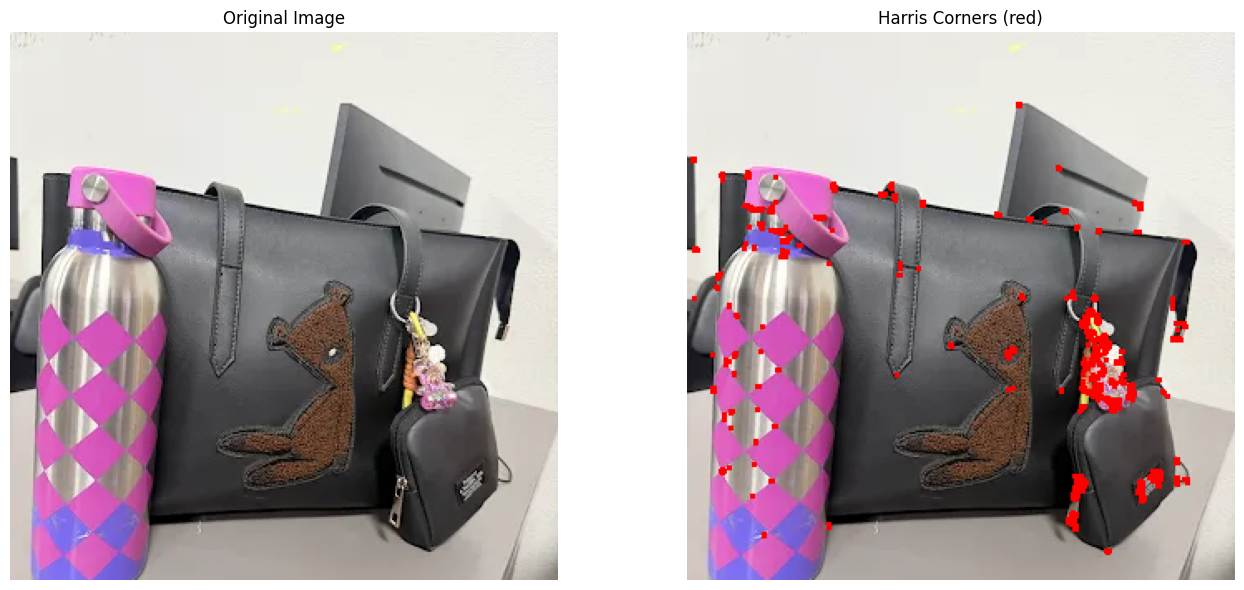

In [16]:
img = load_image(TASK1_IMAGE)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Image size:", img.shape)

BLOCK_SIZE, KSIZE, K = 2, 3, 0.04

def harris_response(gray_img):
    return cv2.cornerHarris(np.float32(gray_img), BLOCK_SIZE, KSIZE, K)

def corner_points(response, thresh_ratio):
    """Return one (x, y) point per detected corner (centroid of each thresholded blob)."""
    mask = np.uint8(response > thresh_ratio * response.max())
    n, _, _, centroids = cv2.connectedComponentsWithStats(mask)
    return centroids[1:]          # label 0 is the background

def draw_corners(rgb, response, thresh_ratio):
    out = rgb.copy()
    dil = cv2.dilate(response, None)      # dilate only so corners are easier to see
    out[dil > thresh_ratio * response.max()] = [255, 0, 0]
    return out

R = harris_response(gray)
pts = corner_points(R, 0.01)
print("Corners detected (threshold = 0.01 x max):", len(pts))

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1); plt.imshow(img_rgb); plt.title("Original Image"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(draw_corners(img_rgb, R, 0.01)); plt.title("Harris Corners (red)"); plt.axis("off")
plt.tight_layout(); plt.show()

## 1.2 Compare three threshold values
The threshold decides how strong the Harris response must be for a pixel to count as a corner. Three values are tried: **0.001**, **0.01** and **0.1** of the maximum response.

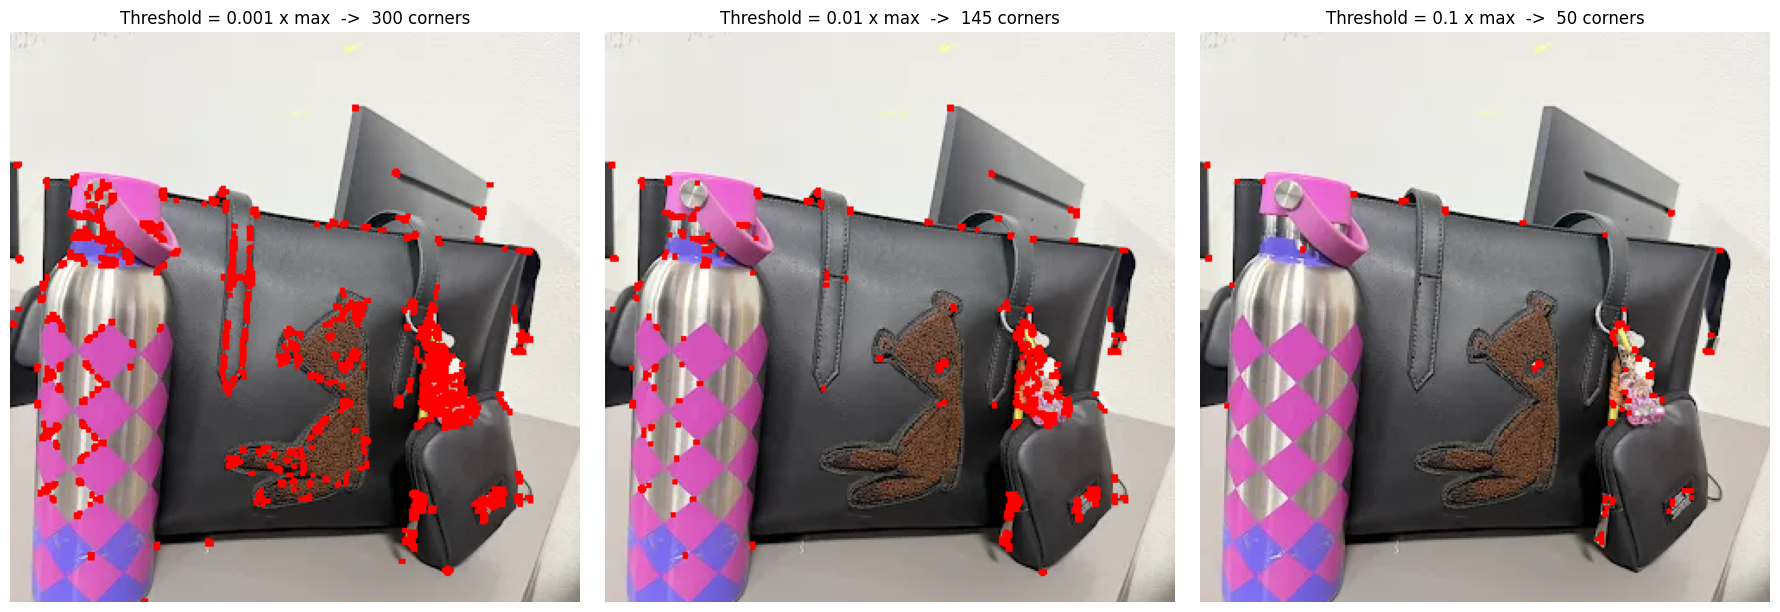

Threshold    Corners
0.001            300
0.01             145
0.1               50


In [6]:
thresholds = [0.001, 0.01, 0.1]
counts = []

plt.figure(figsize=(18, 6))
for i, t in enumerate(thresholds):
    n = len(corner_points(R, t))
    counts.append(n)
    plt.subplot(1, 3, i + 1)
    plt.imshow(draw_corners(img_rgb, R, t))
    plt.title(f"Threshold = {t} x max  ->  {n} corners")
    plt.axis("off")
plt.tight_layout(); plt.show()

print(f"{'Threshold':<12}{'Corners':>8}")
for t, n in zip(thresholds, counts):
    print(f"{t:<12}{n:>8}")

**Observation:**
- **0.001 (low):** many corners are detected, including weak responses from texture, noise and slightly curved edges. More false positives.
- **0.01 (medium):** a good balance — the clear corners of objects are kept and most noise is removed.
- **0.1 (high):** only the very strongest corners survive; many real but weaker corners are missed.

So a **lower threshold increases recall but adds false corners**, while a **higher threshold gives fewer but more reliable corners**. The number of corners drops sharply as the threshold increases (see the table above).

## 1.3 Rotate and resize the image
To test invariance, the image is rotated by 45° and resized to 0.5× and 2×. Harris is applied again with the same parameters (threshold 0.01).

**Repeatability** is measured: each corner from the original image is mapped to its expected position in the transformed image, and it counts as repeated if it and a newly detected corner are each other's nearest neighbour within 3 pixels. The count is divided by the larger of the two corner sets, so both missed corners and extra corners lower the score. High repeatability means the detector is invariant to that transform.

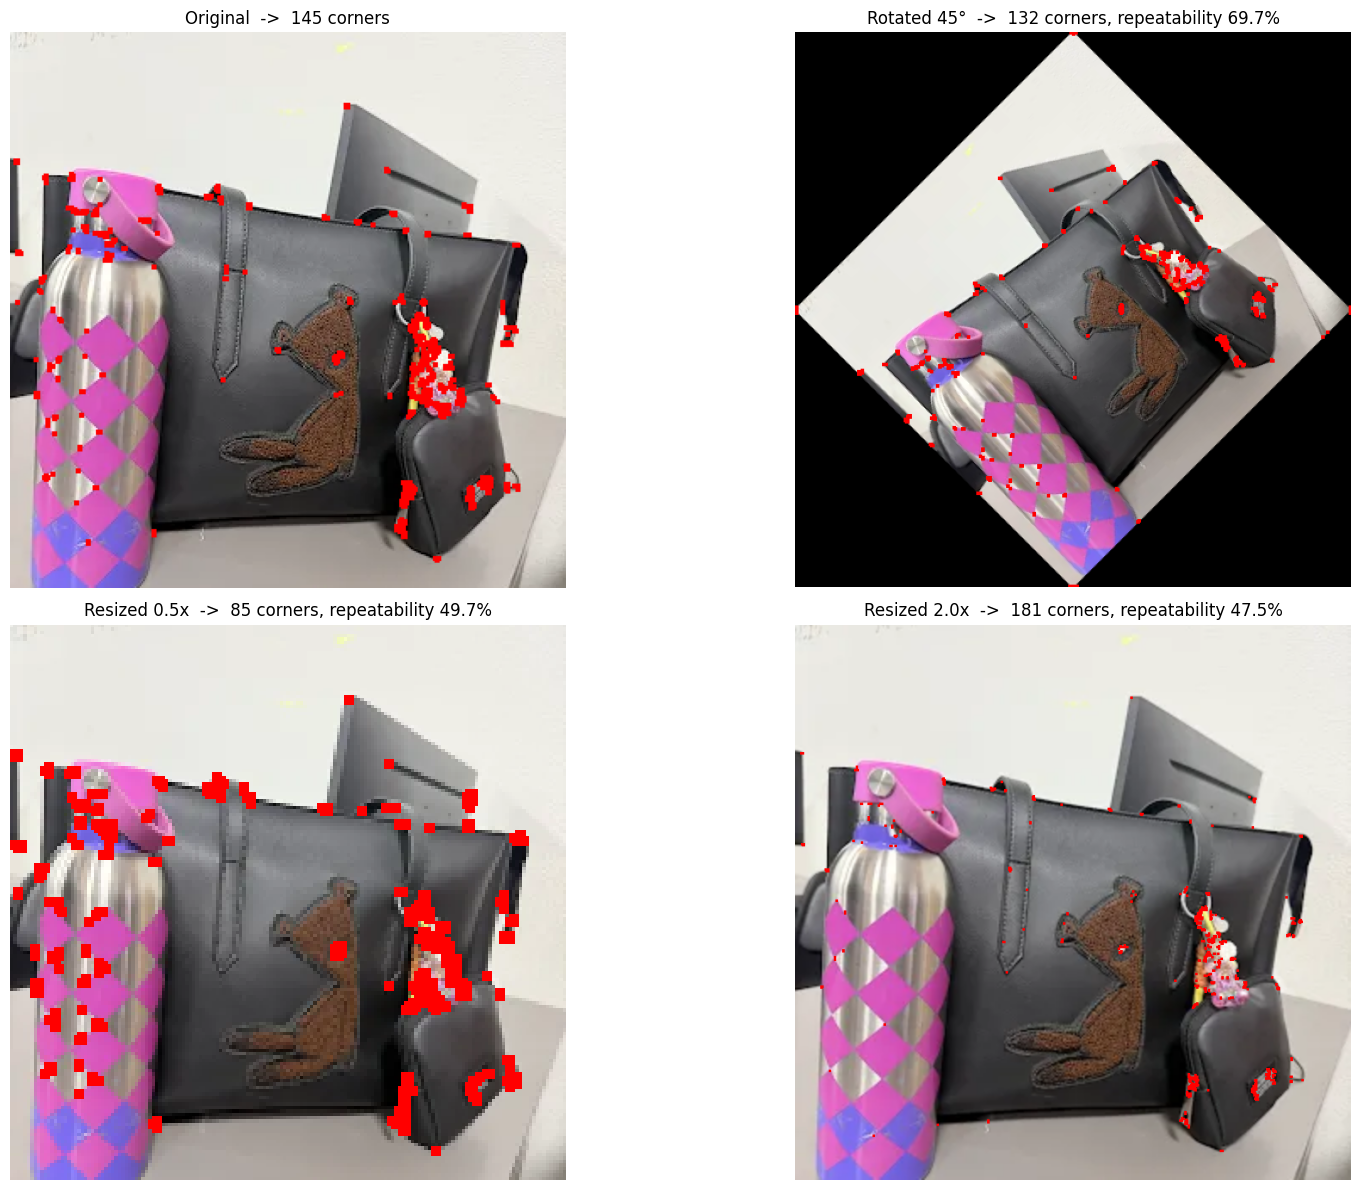

Image          Corners   Repeatability
Original           145               —
Rotated 45°        132           69.7%
Resized 0.5x        85           49.7%
Resized 2.0x       181           47.5%


In [7]:
h, w = gray.shape
THRESH = 0.01
TOL = 3.0   # pixels

def repeatability(orig_pts, A, new_pts, orig_shape):
    """One-to-one repeatability (%):
    1. map original corners into the transformed image using A,
    2. drop new corners that come from the black border (they map back outside the original),
    3. count mutual nearest-neighbour pairs closer than TOL pixels,
    4. divide by the larger of the two corner sets, so detecting extra/fewer corners is penalised."""
    if len(orig_pts) == 0 or len(new_pts) == 0:
        return 0.0
    mapped = cv2.transform(orig_pts.reshape(-1, 1, 2).astype(np.float32), A).reshape(-1, 2)
    A_inv = cv2.invertAffineTransform(A)
    back = cv2.transform(new_pts.reshape(-1, 1, 2).astype(np.float32), A_inv).reshape(-1, 2)
    H0, W0 = orig_shape
    m = 5
    keep = (back[:, 0] >= m) & (back[:, 0] < W0 - m) & (back[:, 1] >= m) & (back[:, 1] < H0 - m)
    new_pts = new_pts[keep]
    if len(new_pts) == 0:
        return 0.0
    d = np.linalg.norm(mapped[:, None, :] - new_pts[None, :, :], axis=2)
    nn_ab = d.argmin(axis=1)          # nearest new corner for each original corner
    nn_ba = d.argmin(axis=0)          # nearest original corner for each new corner
    mutual = sum(1 for i, j in enumerate(nn_ab) if nn_ba[j] == i and d[i, j] <= TOL)
    return 100.0 * mutual / max(len(mapped), len(new_pts))

orig_pts = corner_points(R, THRESH)
results = []

# --- Rotation by 45 degrees (canvas enlarged so nothing is cropped) ---
angle = 45
A_rot = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
cos, sin = abs(A_rot[0, 0]), abs(A_rot[0, 1])
nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
A_rot[0, 2] += nw / 2 - w / 2
A_rot[1, 2] += nh / 2 - h / 2
rot_rgb = cv2.warpAffine(img_rgb, A_rot, (nw, nh))
rot_gray = cv2.warpAffine(gray, A_rot, (nw, nh))
results.append(("Rotated 45°", rot_rgb, rot_gray, A_rot))

# --- Resize 0.5x and 2x ---
for s in [0.5, 2.0]:
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR
    rs_rgb = cv2.resize(img_rgb, None, fx=s, fy=s, interpolation=interp)
    rs_gray = cv2.resize(gray, None, fx=s, fy=s, interpolation=interp)
    A_s = np.array([[s, 0, 0], [0, s, 0]], dtype=np.float64)
    results.append((f"Resized {s}x", rs_rgb, rs_gray, A_s))

plt.figure(figsize=(18, 12))
plt.subplot(2, 2, 1)
plt.imshow(draw_corners(img_rgb, R, THRESH))
plt.title(f"Original  ->  {len(orig_pts)} corners"); plt.axis("off")

summary = [("Original", len(orig_pts), "—")]
for i, (name, rgb_t, gray_t, A) in enumerate(results):
    R_t = harris_response(gray_t)
    pts_t = corner_points(R_t, THRESH)
    rep = repeatability(orig_pts, A, pts_t, gray.shape)
    summary.append((name, len(pts_t), f"{rep:.1f}%"))
    plt.subplot(2, 2, i + 2)
    plt.imshow(draw_corners(rgb_t, R_t, THRESH))
    plt.title(f"{name}  ->  {len(pts_t)} corners, repeatability {rep:.1f}%")
    plt.axis("off")
plt.tight_layout(); plt.show()

print(f"{'Image':<14}{'Corners':>8}{'Repeatability':>16}")
for name, n, rep in summary:
    print(f"{name:<14}{n:>8}{rep:>16}")

## 1.4 Why Harris is **not** scale invariant
**Rotation:** Harris is (mostly) **rotation invariant**. The response depends on the two eigenvalues of the matrix $M$. Rotating the image rotates the gradient directions, which only rotates the eigenvectors — the eigenvalues stay the same. So most of the same points are still detected as corners — repeatability for the rotated image is clearly higher than for the resized ones. The loss that remains comes from interpolation during rotation and the 3×3 Sobel filter, which measures gradients more accurately along the pixel grid than at 45°.

**Scale:** Harris uses a **fixed window size** (`blockSize = 2`, `ksize = 3`) at a single scale. Whether a structure looks like a corner depends on how big it is compared to this window:
- When the image is **enlarged (2×)**, a sharp corner is spread over many pixels. Inside the small fixed window it now looks like a smooth curve or a straight **edge**, so it is no longer detected — or one corner breaks into several responses.
- When the image is **shrunk (0.5×)**, small corners and fine texture merge together or disappear, and several nearby corners collapse into one.

So the set of detected corners **changes with the image size**, and repeatability drops for the resized images. Harris has no mechanism to pick the "right" window size for each feature.

**How SIFT solves this:** SIFT searches over a **scale space** (Difference of Gaussians at many scales) and picks the characteristic scale of each keypoint, so the same feature is found whether the image is large or small. That is why SIFT is used for matching in Task 2.

---
# Lab Task 2 — SIFT Matching, RANSAC Homography and Panorama
## 2.1 Load the two overlapping photos

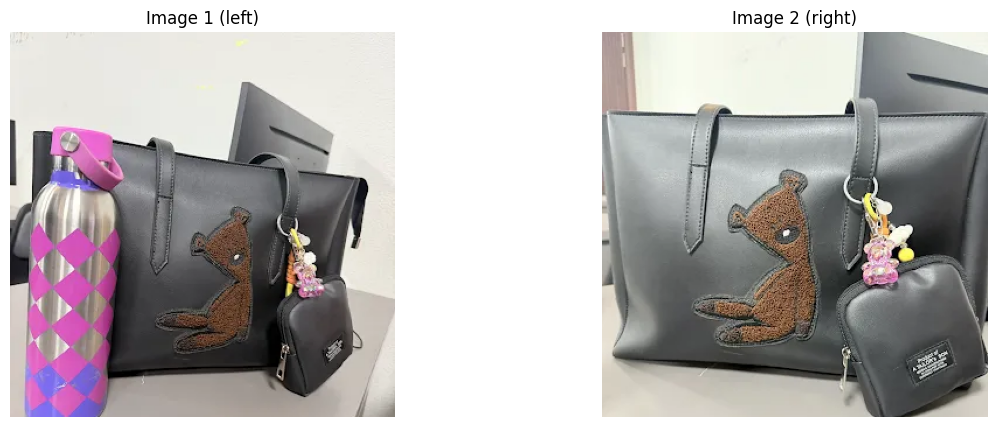

Image 1 size: (330, 330, 3)
Image 2 size: (330, 330, 3)


In [8]:
img1 = load_image(LEFT_IMAGE)
img2 = load_image(RIGHT_IMAGE)
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1); plt.imshow(img1_rgb); plt.title("Image 1 (left)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(img2_rgb); plt.title("Image 2 (right)"); plt.axis("off")
plt.show()
print("Image 1 size:", img1.shape)
print("Image 2 size:", img2.shape)

## 2.2 Detect SIFT keypoints and descriptors

Keypoints in Image 1: 300
Keypoints in Image 2: 249
Descriptor shape 1: (300, 128)
Descriptor shape 2: (249, 128)


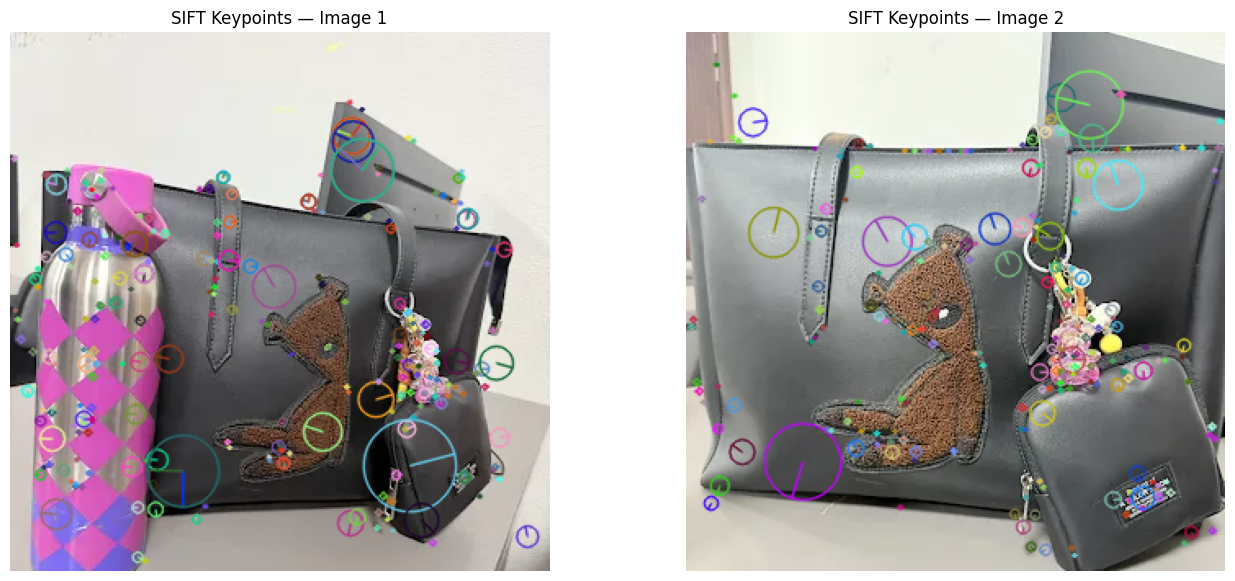

In [9]:
sift = cv2.SIFT_create()
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

print("Keypoints in Image 1:", len(keypoints1))
print("Keypoints in Image 2:", len(keypoints2))
print("Descriptor shape 1:", descriptors1.shape)
print("Descriptor shape 2:", descriptors2.shape)

vis1 = cv2.drawKeypoints(img1_rgb, keypoints1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
vis2 = cv2.drawKeypoints(img2_rgb, keypoints2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1); plt.imshow(vis1); plt.title("SIFT Keypoints — Image 1"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(vis2); plt.title("SIFT Keypoints — Image 2"); plt.axis("off")
plt.show()

## 2.3 Match descriptors + Lowe's ratio test
Brute-force matcher with L2 distance finds the 2 nearest neighbours for every descriptor. A match is kept only if $d_1 < 0.75\,d_2$ (best match clearly better than the second best).

Total candidate matches: 300
Good matches after ratio test: 10
Kept: 3.3%


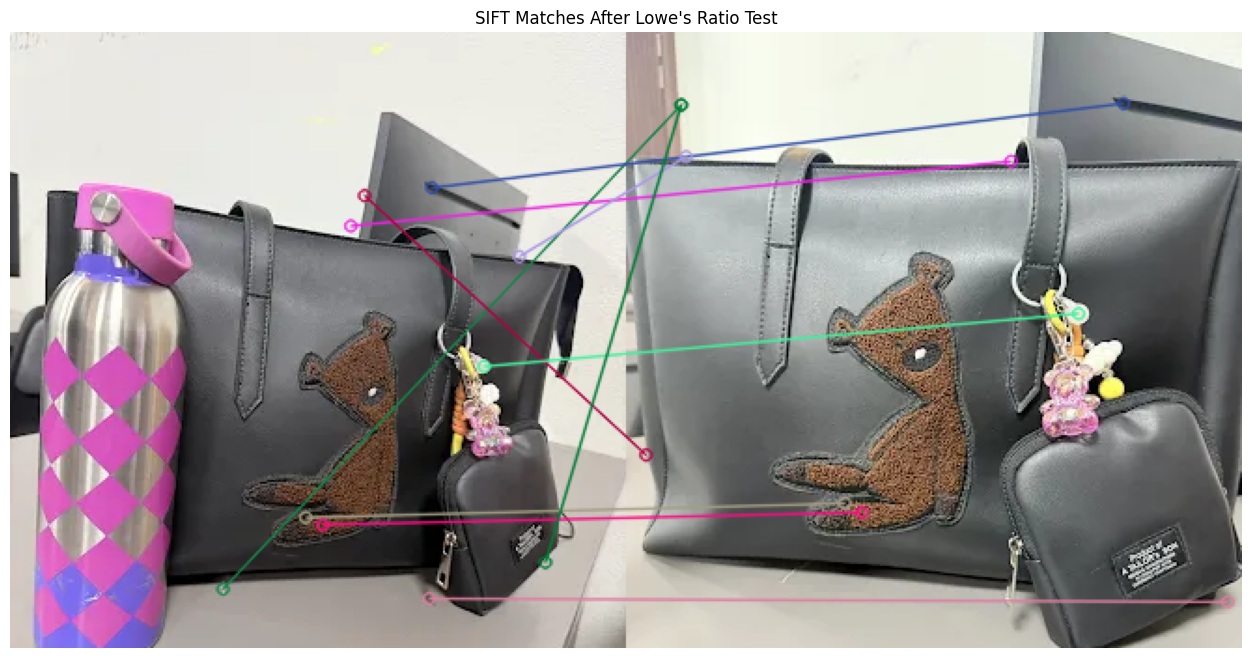

In [10]:
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
matches_knn = bf.knnMatch(descriptors1, descriptors2, k=2)

ratio_threshold = 0.75
good_matches = []
for pair in matches_knn:
    if len(pair) == 2:
        m, n = pair
        if m.distance < ratio_threshold * n.distance:
            good_matches.append(m)

print("Total candidate matches:", len(matches_knn))
print("Good matches after ratio test:", len(good_matches))
print(f"Kept: {100 * len(good_matches) / len(matches_knn):.1f}%")

match_img = cv2.drawMatches(img1_rgb, keypoints1, img2_rgb, keypoints2, good_matches, None,
                            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(18, 8))
plt.imshow(match_img); plt.title("SIFT Matches After Lowe's Ratio Test"); plt.axis("off")
plt.show()

## 2.4 Estimate homography with RANSAC and report inliers
RANSAC repeatedly fits a homography to 4 random correspondences and counts how many matches agree within 5 px reprojection error. The best model's agreeing matches are the **inliers**.

In [11]:
if len(good_matches) < 4:
    raise ValueError("At least 4 good matches are required to estimate a homography.")

src_pts = np.float32([keypoints1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([keypoints2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
if H is None:
    raise RuntimeError("Homography could not be estimated.")

mask = mask.ravel()
inlier_matches  = [m for m, keep in zip(good_matches, mask) if keep]
outlier_matches = [m for m, keep in zip(good_matches, mask) if not keep]

print("Total good matches:", len(good_matches))
print("RANSAC inliers   :", len(inlier_matches))
print("RANSAC outliers  :", len(outlier_matches))
print(f"Inlier ratio     : {len(inlier_matches) / len(good_matches):.4f}")
print("\nHomography matrix H:\n", np.round(H, 5))

Total good matches: 10
RANSAC inliers   : 5
RANSAC outliers  : 5
Inlier ratio     : 0.5000

Homography matrix H:
 [[ 2.7424400e+00 -3.3231000e-01 -8.5659400e+01]
 [ 4.5350000e-02  2.8223800e+00 -1.7334954e+02]
 [ 2.9200000e-03  2.9700000e-03  1.0000000e+00]]


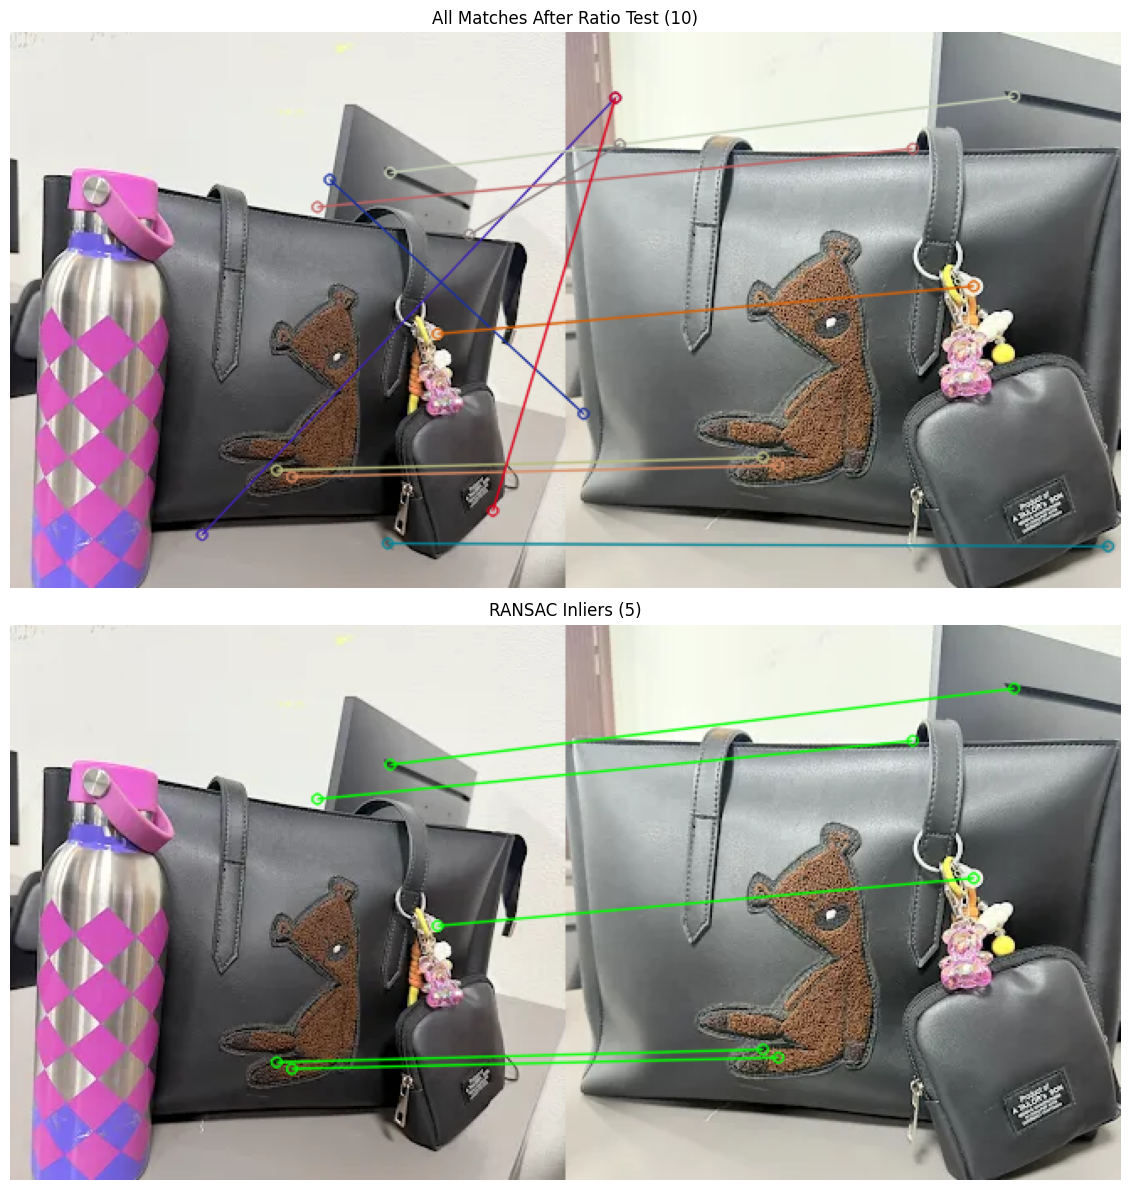

In [12]:
plt.figure(figsize=(18, 12))
plt.subplot(2, 1, 1)
plt.imshow(cv2.drawMatches(img1_rgb, keypoints1, img2_rgb, keypoints2, good_matches, None,
                           flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS))
plt.title(f"All Matches After Ratio Test ({len(good_matches)})"); plt.axis("off")
plt.subplot(2, 1, 2)
plt.imshow(cv2.drawMatches(img1_rgb, keypoints1, img2_rgb, keypoints2, inlier_matches, None,
                           matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS))
plt.title(f"RANSAC Inliers ({len(inlier_matches)})"); plt.axis("off")
plt.tight_layout(); plt.show()

## 2.5 Stitch the images into a panorama
$H$ maps Image 1 → Image 2. Image 1 is warped into Image 2's coordinate system, the canvas size is found from the warped corners, a translation keeps all coordinates positive, and the overlap is blended 50/50.

Panorama size: (557, 517, 3)


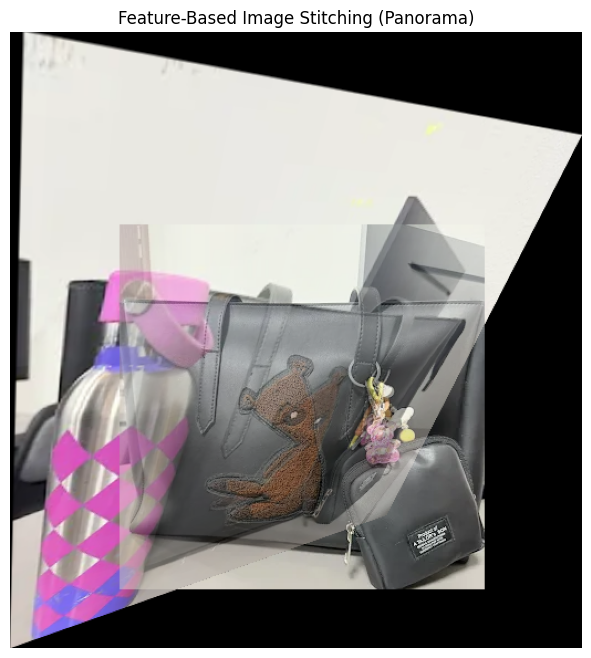

In [13]:
def simple_feature_stitch(image1, image2, homography):
    h1, w1 = image1.shape[:2]
    h2, w2 = image2.shape[:2]

    corners1 = np.float32([[0, 0], [w1, 0], [w1, h1], [0, h1]]).reshape(-1, 1, 2)
    corners2 = np.float32([[0, 0], [w2, 0], [w2, h2], [0, h2]]).reshape(-1, 1, 2)
    warped_corners1 = cv2.perspectiveTransform(corners1, homography)

    all_corners = np.concatenate([corners2, warped_corners1], axis=0)
    xmin, ymin = np.floor(all_corners.min(axis=0).ravel()).astype(int)
    xmax, ymax = np.ceil(all_corners.max(axis=0).ravel()).astype(int)

    tx, ty = -xmin, -ymin
    translation = np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=np.float64)
    canvas_w, canvas_h = int(xmax - xmin), int(ymax - ymin)

    warped1 = cv2.warpPerspective(image1, translation @ homography, (canvas_w, canvas_h))
    warped_mask = cv2.warpPerspective(np.ones((h1, w1), dtype=np.uint8),
                                      translation @ homography, (canvas_w, canvas_h))

    image2_canvas = np.zeros_like(warped1)
    image2_canvas[ty:ty + h2, tx:tx + w2] = image2
    image2_mask = np.zeros((canvas_h, canvas_w), dtype=np.uint8)
    image2_mask[ty:ty + h2, tx:tx + w2] = 1

    panorama = warped1.copy()
    overlap = (warped_mask > 0) & (image2_mask > 0)
    only_image2 = (warped_mask == 0) & (image2_mask > 0)

    panorama[overlap] = (0.5 * warped1[overlap] + 0.5 * image2_canvas[overlap]).astype(np.uint8)
    panorama[only_image2] = image2_canvas[only_image2]
    return panorama

panorama = simple_feature_stitch(img1, img2, H)
cv2.imwrite("panorama.jpg", panorama)
print("Panorama size:", panorama.shape)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title("Feature-Based Image Stitching (Panorama)"); plt.axis("off")
plt.show()

## 2.6 Results summary

In [14]:
print("=" * 44)
print(f"{'Keypoints (Image 1 / Image 2)':<32}{len(keypoints1)} / {len(keypoints2)}")
print(f"{'Candidate matches (kNN)':<32}{len(matches_knn)}")
print(f"{'Good matches (ratio 0.75)':<32}{len(good_matches)}")
print(f"{'RANSAC inliers':<32}{len(inlier_matches)}")
print(f"{'RANSAC outliers':<32}{len(outlier_matches)}")
print(f"{'Inlier ratio':<32}{100 * len(inlier_matches) / len(good_matches):.1f}%")
print("=" * 44)

Keypoints (Image 1 / Image 2)   300 / 249
Candidate matches (kNN)         300
Good matches (ratio 0.75)       10
RANSAC inliers                  5
RANSAC outliers                 5
Inlier ratio                    50.0%


**Observation:**
- SIFT finds thousands of keypoints in both photos because it detects features at multiple scales and orientations.
- Lowe's ratio test removes the ambiguous matches (repeated patterns, plain areas) and keeps only distinctive ones.
- RANSAC removes the remaining wrong matches: only correspondences consistent with a single homography are kept as **inliers** (count reported above). A high inlier ratio means the ratio test already removed most false matches.
- The panorama aligns well in the overlap region. Small ghosting or seams can appear where the scene is not planar (parallax from objects at different depths), where something moved between the two shots, or where the exposure differs — because a single homography and a simple 50/50 blend are used.